# SONG tuning candidates: exploratory sweep

This **one-seed** sweep profiles a few current constructor parameters on the same 600-digit subset as `01_static_baseline.ipynb`. It is intended to prioritize experiments, not to select a new default. All runs use the unmodified `UMAP_dispersion` branch at `4c711c8`, with `dispersion_method='UMAP'` and common seed 42. The SONG constructor exposes `um_epochs`, `um_lr` and `um_min_dist`, but the current implementation does not pass them to UMAP; they are excluded from this sweep until that is fixed. Results will vary with seed and dataset; any winning configuration needs repeated trials and a held-out biological dataset.

Runtime includes both `fit` and `transform` after JIT warm-up. Quality metrics are trustworthiness @10 and k-means ARI, plus a transductive kNN label probe. UMAP is a contextual reference with its own default epoch budget.

In [1]:
import os, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.manifold import trustworthiness
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from umap import UMAP
from song.song import SONG
fig_dir=Path('reports/figures'); fig_dir.mkdir(parents=True, exist_ok=True)
digits=load_digits()
indices=np.random.default_rng(42).permutation(len(digits.data))[:600]
X=(digits.data[indices]/16).astype(np.float32)
labels=digits.target[indices]
SONG(so_steps=2, final_vector_count=16, dispersion_method='none').fit_transform(X[:80])
SONG(so_steps=2,final_vector_count=16,dispersion_method='UMAP').fit_transform(X[:80])
UMAP(n_neighbors=15,n_epochs=11,random_state=42).fit_transform(X[:80])
print('N=',len(X),'D=',X.shape[1],'Numba threads=',os.environ.get('NUMBA_NUM_THREADS','default'))

/Users/damith/personal/SONG/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/damith/personal/SONG/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


N= 600 D= 64 Numba threads= 2


In [2]:
configs=[
 ('baseline short', dict(so_steps=10, final_vector_count=48, n_neighbors=1, spread_factor=.9, ns_rate=5)),
 ('default steps', dict(so_steps=100, final_vector_count=48, n_neighbors=1, spread_factor=.9, ns_rate=5)),
 ('30 steps', dict(so_steps=30, final_vector_count=48, n_neighbors=1, spread_factor=.9, ns_rate=5)),
 ('more coding vectors', dict(so_steps=30, final_vector_count=96, n_neighbors=1, spread_factor=.9, ns_rate=5)),
 ('3 graph neighbors', dict(so_steps=30, final_vector_count=48, n_neighbors=3, spread_factor=.9, ns_rate=5)),
 ('smaller spread factor', dict(so_steps=30, final_vector_count=48, n_neighbors=1, spread_factor=.5, ns_rate=5)),
 ('fewer negative samples', dict(so_steps=30, final_vector_count=48, n_neighbors=1, spread_factor=.9, ns_rate=2)),
 ('no PCA on 64D digits', dict(so_steps=30, final_vector_count=48, n_neighbors=1, spread_factor=.9, ns_rate=5, pc_components=64)),
]
cv=StratifiedKFold(5,shuffle=True,random_state=42)
rows=[]
embeddings={}
for name, params in configs:
    t0=time.perf_counter()
    model=SONG(random_seed=42,chunk_size=128,dispersion_method='UMAP',**params)
    Y=model.fit_transform(X)
    elapsed=time.perf_counter()-t0
    embeddings[name]=Y.copy()
    assert Y.shape==(len(X),2) and np.isfinite(Y).all()
    clusters=KMeans(n_clusters=10,n_init=10,random_state=42).fit_predict(Y)
    rows.append({'config':name,**params,'total_s':elapsed,'trustworthiness':trustworthiness(X,Y,n_neighbors=10),
                 'kmeans_ARI':adjusted_rand_score(labels,clusters), 'kmeans_AMI':adjusted_mutual_info_score(labels,clusters),
                 'kNN_probe_accuracy':cross_val_score(KNeighborsClassifier(n_neighbors=5),Y,labels,cv=cv).mean(),
                 'actual_prototypes':len(model.W)})
    print(name, f"{elapsed:.3f}s", f"trust={rows[-1]['trustworthiness']:.3f}",f"ARI={rows[-1]['kmeans_ARI']:.3f}")
results=pd.DataFrame(rows)
display(results.round(3))
results.to_csv('reports/tuning_sweep.csv',index=False)

baseline short 0.124s trust=0.852 ARI=0.213


default steps 0.419s trust=0.822 ARI=0.148


30 steps 0.198s trust=0.853 ARI=0.303


more coding vectors 0.211s trust=0.830 ARI=0.146


3 graph neighbors 0.223s trust=0.852 ARI=0.218


smaller spread factor 0.195s trust=0.869 ARI=0.231


fewer negative samples 0.191s trust=0.862 ARI=0.231


no PCA on 64D digits 0.183s trust=0.978 ARI=0.809


,config,so_steps,final_vector_count,n_neighbors,spread_factor,ns_rate,total_s,trustworthiness,kmeans_ARI,kmeans_AMI,kNN_probe_accuracy,actual_prototypes,pc_components
0,baseline short,10,48,1,0.9,5,0.124,0.852,0.213,0.338,0.632,55,NaN
1,default steps,100,48,1,0.9,5,0.419,0.822,0.148,0.265,0.617,66,NaN
2,30 steps,30,48,1,0.9,5,0.198,0.853,0.303,0.413,0.672,56,NaN
3,more coding vectors,30,96,1,0.9,5,0.211,0.830,0.146,0.287,0.585,113,NaN
4,3 graph neighbors,30,48,3,0.9,5,0.223,0.852,0.218,0.348,0.640,49,NaN
5,smaller spread factor,30,48,1,0.5,5,0.195,0.869,0.231,0.365,0.663,58,NaN
6,fewer negative samples,30,48,1,0.9,2,0.191,0.862,0.231,0.369,0.682,56,NaN
7,no PCA on 64D digits,30,48,1,0.9,5,0.183,0.978,0.809,0.854,0.962,79,64.0


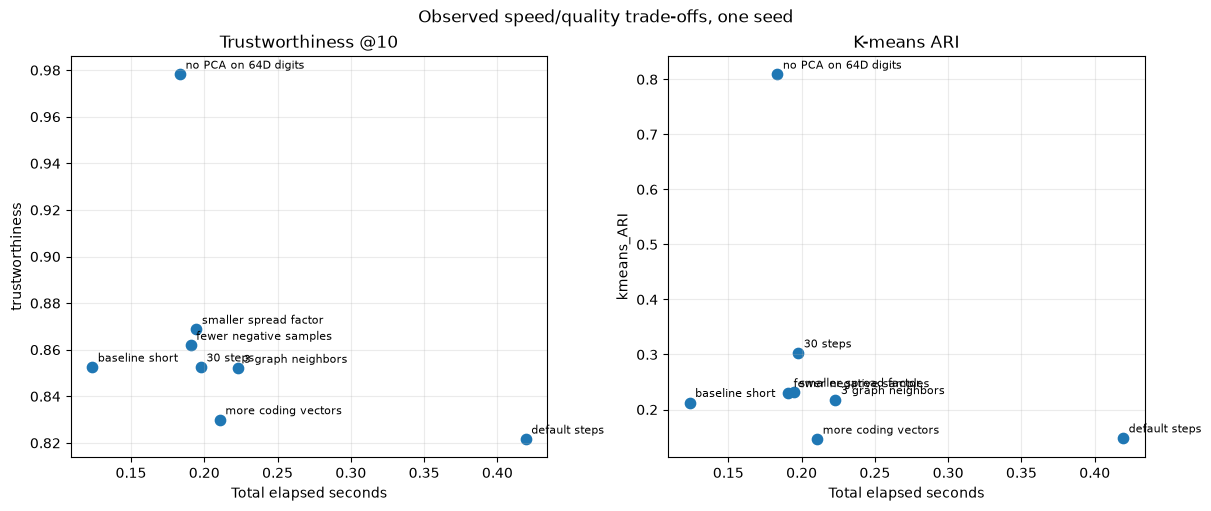

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
for ax,metric,title in zip(axes,['trustworthiness','kmeans_ARI'],['Trustworthiness @10','K-means ARI']):
    ax.scatter(results.total_s,results[metric],s=55)
    for _,row in results.iterrows(): ax.annotate(row['config'],(row.total_s,row[metric]),xytext=(4,4),textcoords='offset points',fontsize=8)
    ax.set_xlabel('Total elapsed seconds')
    ax.set_ylabel(metric)
    ax.set_title(title)
    ax.grid(alpha=.25)
fig.suptitle('Observed speed/quality trade-offs, one seed')
fig.savefig(fig_dir/'tuning_tradeoffs.png',dpi=150)
plt.show()

## Follow-up criteria

Repeat promising settings over at least five random seeds and across synthetic, digit and single-cell cohorts. Compare both training and held-out transforms, record JIT warm-up and peak RSS separately, and use matched compute budgets for UMAP comparisons. Do not change defaults based on this one-seed report. The paper's key incremental/noise claims also need their own tests.

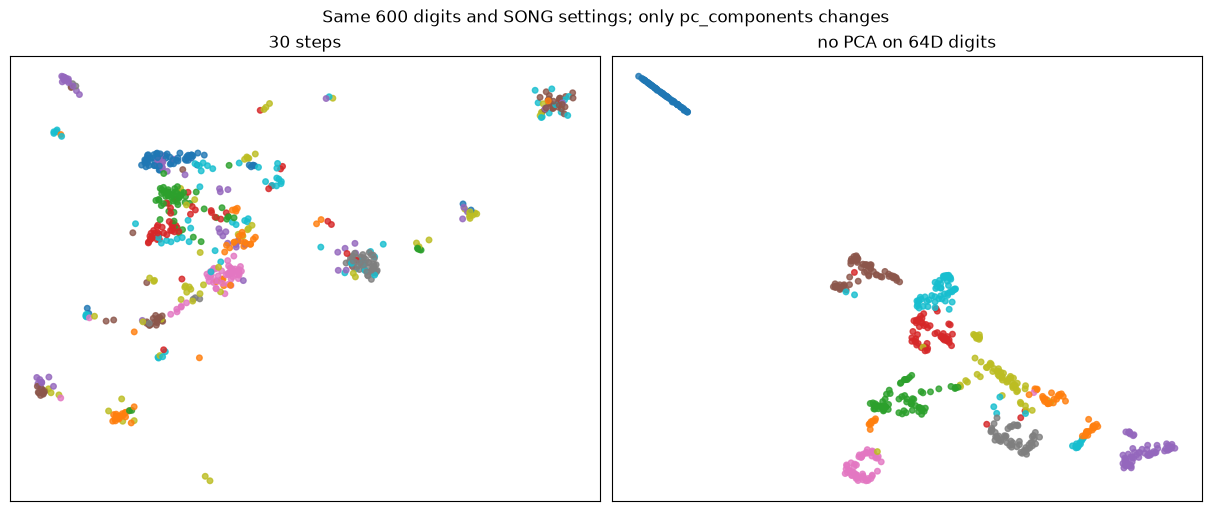

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, name in zip(axes, ['30 steps', 'no PCA on 64D digits']):
    Y = embeddings[name]
    ax.scatter(Y[:, 0], Y[:, 1], c=labels, cmap='tab10', vmin=0, vmax=9,
               s=16, alpha=.8, rasterized=True)
    ax.set_title(name)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('Same 600 digits and SONG settings; only pc_components changes')
fig.savefig(fig_dir/'pca_path_impact.png', dpi=180)
plt.show()